### Практическое задание №4 (12 баллов). Предсказание рейтинга настольных игр
В этом задании вам предстоит предсказывать средний рейтинг настольной игры (Rating Average) на основе различных характеристик игр. Вам будут доступны данные о каждой игре: название, количество игроков, продолжительность партии, жанр, возрастное ограничение, количество рейтингов и отзывы пользователей, год выпуска и прочие метаданные.

Данный датасет основан на информации, собранной с веб-сайта BoardGameGeek (BGG) в феврале 2021 года. BGG — крупнейшая онлайн-коллекция данных о настольных играх, которая включает сведения более чем о 100 000 играх.

Набор данных, предоставленный для этого соревнования, содержит все игры с рейтингами (около 20 000 игр) на момент сбора.

Ваша задача — построить модель, которая сможет предсказывать средний рейтинг игры на основе предоставленных характеристик.

### Критерии оценивания

Анализ данных и их предобработка	0-3 балла

Feature Engineering и отбор признаков	0-2 балла

Выбор и обучение нескольких моделей	0-3 балла

Подбор гиперпараметров и объяснение выбора лучшей модели	0-2 балла

Результат на Kaggle	0-1 балл

Качество оформления ноутбука (чистый код, комментарии, выводы)	0-1 балл

Итого	12 баллов

### Что нужно сделать
1. Принять участие в соревновании на Kaggle:

2. Разработать и оформить решение в ноутбуке:

2.1 Исследование и анализ датасета.

2.2. Предобработка данных.

2.3. Feature Engineering (если необходимо).

2.4. Подбор признаков, их анализ и оценка важности.

2.5. Обучение нескольких моделей, их сравнение.

2.6. Подбор гиперпараметров.

2.7. Выбор лучшей модели и объяснение выбора.

2.8. Предсказание на тестовых данных.

3. Закрепить в ноутбуке скриншот с лидерборда Kaggle.

4. Прикрепить ноутбук (.ipynb) с решением на платформу.

Требования к ноутбуку:

Комментарии и пояснения к коду.

Выводы к каждому этапу (анализ данных, предобработка, обучение).

Код должен быть чистым и читаемым.

In [31]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, MultiLabelBinarizer, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

### 2.1 Исследование и анализ датасета.

In [32]:
# Загружаем тренировочный датасет
file_path = r"C:\IDE\2 семестр\Классическое МО\data\games-rating\train_data.csv" 
train_game = pd.read_csv(file_path, sep=',')

In [33]:
# Загружаем тестовый датасет
file_path1 = r"C:\IDE\2 семестр\Классическое МО\data\games-rating\test_data.csv" 
test_game = pd.read_csv(file_path1, sep=',')


In [34]:
#Ознакамливаемся с датасетом
train_game.head()

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,"8,79",1,"3,86",68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,"8,66",3,"3,91",28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
2,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,"8,43",4,"3,24",87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
3,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,"8,70",5,"4,22",16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"
4,291457.0,Gloomhaven: Jaws of the Lion,2020.0,1,4,120,14,8392,"8,87",6,"3,55",21609.0,"Action Queue, Campaign / Battle Card Driven, C...","Strategy Games, Thematic Games"


In [35]:
#Проверяем типы данных и наличие пропусков
train_game.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15257 entries, 0 to 15256
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  15247 non-null  float64
 1   Name                15257 non-null  object 
 2   Year Published      15256 non-null  float64
 3   Min Players         15257 non-null  int64  
 4   Max Players         15257 non-null  int64  
 5   Play Time           15257 non-null  int64  
 6   Min Age             15257 non-null  int64  
 7   Users Rated         15257 non-null  int64  
 8   Rating Average      15257 non-null  object 
 9   BGG Rank            15257 non-null  int64  
 10  Complexity Average  15257 non-null  object 
 11  Owned Users         15240 non-null  float64
 12  Mechanics           14057 non-null  object 
 13  Domains             7608 non-null   object 
dtypes: float64(3), int64(6), object(5)
memory usage: 1.6+ MB


In [36]:
train_game['Mechanics'].value_counts()

Mechanics
Hand Management                                                                                                                                                                                                                                                                                                                                            327
Hexagon Grid                                                                                                                                                                                                                                                                                                                                               299
Dice Rolling                                                                                                                                                                                                                                                                                    

In [8]:
train_game['Domains'].value_counts()

Domains
Wargames                                          2236
Strategy Games                                    1103
Family Games                                      1004
Abstract Games                                     653
Children's Games                                   526
Thematic Games                                     485
Party Games                                        305
Family Games, Strategy Games                       269
Customizable Games                                 190
Strategy Games, Thematic Games                     164
Thematic Games, Wargames                           110
Family Games, Party Games                          101
Family Games, Thematic Games                        89
Abstract Games, Family Games                        84
Children's Games, Family Games                      73
Strategy Games, Wargames                            71
Abstract Games, Strategy Games                      26
Customizable Games, Strategy Games                  21
Pa

Вывод:

В датасете представлены 15257 сэмплов, 1 целевая переменная, 13 признаков. В столбцах Year Published, Owned Users незначительное количество пропусков. В столбцах Mechanics, Domains присутствует значительное количество пропусков, кроме того они множественно категориальные, что усложнит их обработку. Также столбцы  Rating Average, Name, Complexity Average нечисловые, что потребует их обработки.

### 2.2. Предобработка данных.

In [9]:
# Создаем копии датасетов
train_game_copy = train_game.copy()
test_game_copy = test_game.copy()

In [10]:
# Обрабатываем нечисловые признаки
train_game_copy['Rating Average'] = train_game_copy['Rating Average'].str.replace(',', '.').astype(float)
train_game_copy['Complexity Average'] = train_game_copy['Complexity Average'].str.replace(',', '.').astype(float)
test_game_copy['Complexity Average'] = test_game_copy['Complexity Average'].str.replace(',', '.').astype(float)

In [11]:
# Заполняем пропуски в столбцах с незначительным их количеством. В тестовых данных пропуски заполняем медианой, рассчитанной на тренировочных данных.
median_users = train_game_copy["Owned Users"].median()
median_year = train_game_copy["Year Published"].median()

train_game_copy["Owned Users"] = train_game_copy["Owned Users"].fillna(median_users)
train_game_copy["Year Published"] = train_game_copy["Year Published"].fillna(median_year)

test_game_copy["Owned Users"] = test_game_copy["Owned Users"].fillna(median_users)
test_game_copy["Year Published"] = test_game_copy["Year Published"].fillna(median_year)

In [12]:
# Удаляем неинформативные, излишне индивидуальные признаки
train_game_copy = train_game_copy.drop(['ID', 'Name'], axis=1)
test_game_copy = test_game_copy.drop(['ID', 'Name'], axis=1)

In [13]:
# Удаляем категориальные признаки, с большим количеством пропусков
train_game_copy = train_game_copy.drop(['Mechanics', 'Domains'], axis=1)
test_game_copy = test_game_copy.drop(['Mechanics', 'Domains'], axis=1)

In [14]:
train_game_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15257 entries, 0 to 15256
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Year Published      15257 non-null  float64
 1   Min Players         15257 non-null  int64  
 2   Max Players         15257 non-null  int64  
 3   Play Time           15257 non-null  int64  
 4   Min Age             15257 non-null  int64  
 5   Users Rated         15257 non-null  int64  
 6   Rating Average      15257 non-null  float64
 7   BGG Rank            15257 non-null  int64  
 8   Complexity Average  15257 non-null  float64
 9   Owned Users         15257 non-null  float64
dtypes: float64(4), int64(6)
memory usage: 1.2 MB


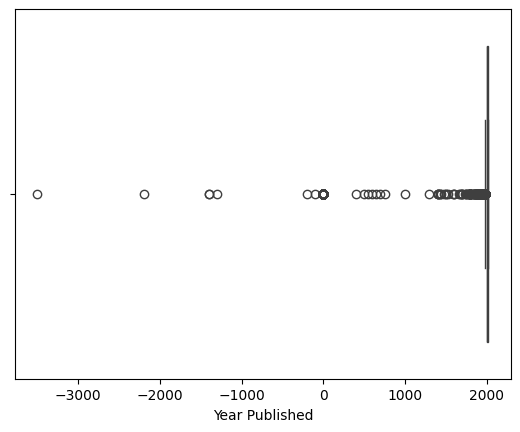

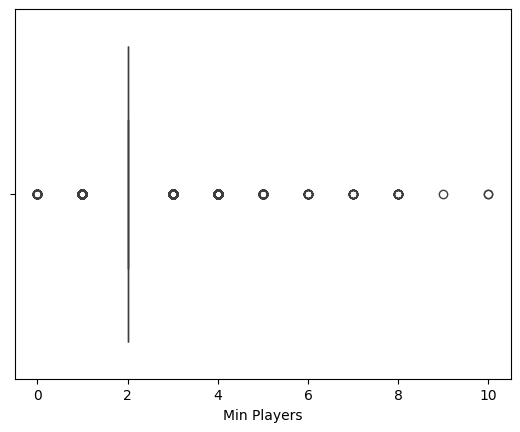

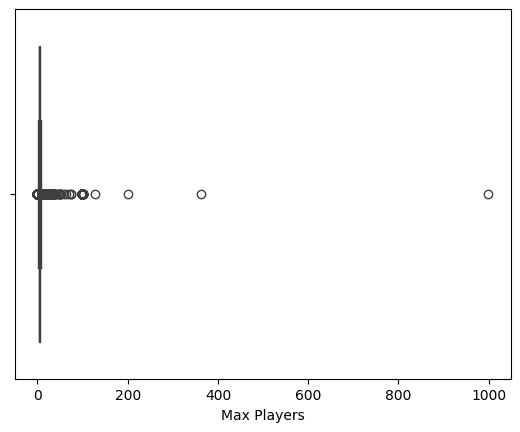

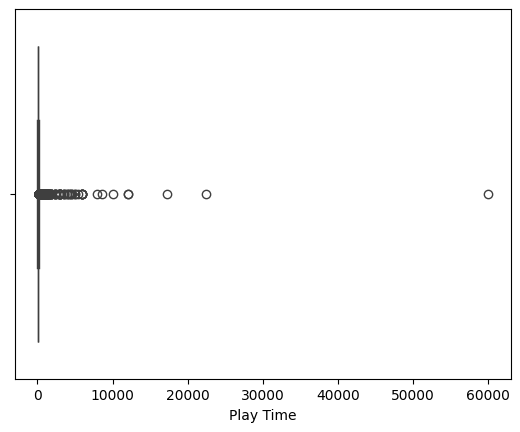

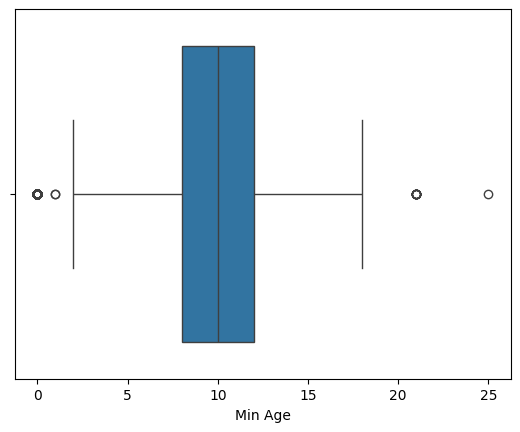

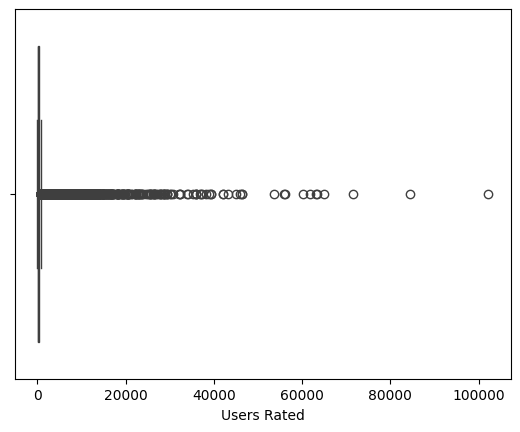

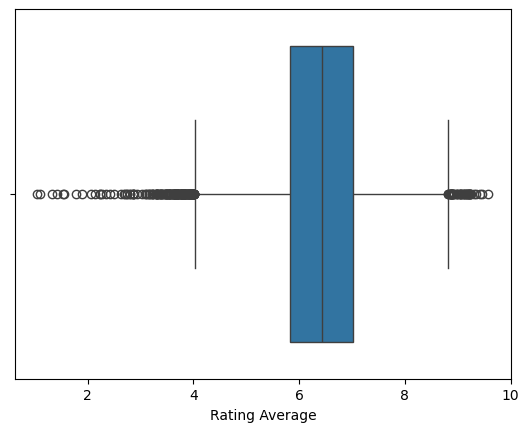

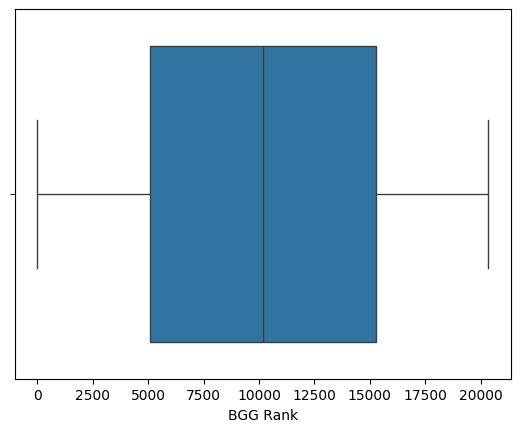

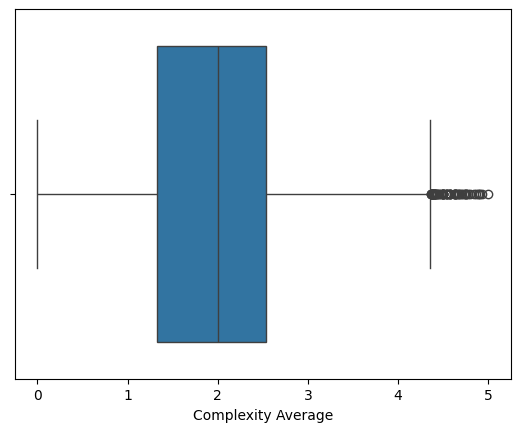

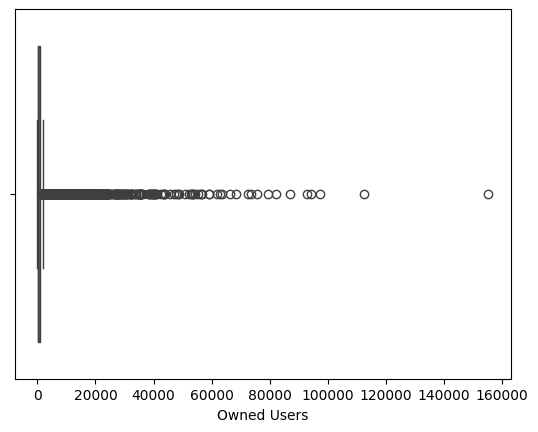

In [15]:
# Рассмотрим наличие выбросов в данных
for i in train_game_copy.columns:
    sns.boxplot(x=train_game_copy[i])
    plt.show()

In [16]:
# Удаляем строки с выбросами, при определении выбросов, руководствуемся здравым смыслом и оценочным суждением
train_game_copy = train_game_copy[(train_game_copy['Year Published'] > 1940.0)]
train_game_copy = train_game_copy[(train_game_copy['Min Age'] > 2)]
train_game_copy = train_game_copy[(train_game_copy['Play Time'] < 8000)]
train_game_copy = train_game_copy[(train_game_copy['Min Players'] > 0)]
train_game_copy = train_game_copy[train_game_copy['Max Players'].between(1, 150)]

In [17]:
train_game_copy.head()

,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users
0,2017.0,1,4,120,14,42055,8.79,1,3.86,68323.0
1,2018.0,2,4,120,14,19217,8.66,3,3.91,28785.0
2,2016.0,1,5,120,12,64864,8.43,4,3.24,87099.0
3,2017.0,3,6,480,14,13468,8.70,5,4.22,16831.0
4,2020.0,1,4,120,14,8392,8.87,6,3.55,21609.0


In [18]:
train_game_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13956 entries, 0 to 15254
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Year Published      13956 non-null  float64
 1   Min Players         13956 non-null  int64  
 2   Max Players         13956 non-null  int64  
 3   Play Time           13956 non-null  int64  
 4   Min Age             13956 non-null  int64  
 5   Users Rated         13956 non-null  int64  
 6   Rating Average      13956 non-null  float64
 7   BGG Rank            13956 non-null  int64  
 8   Complexity Average  13956 non-null  float64
 9   Owned Users         13956 non-null  float64
dtypes: float64(4), int64(6)
memory usage: 1.2 MB


Вывод:

В данном разделе были удалены неинформативные признаки, заполнены пропуски, обработаны нечисловые признаки, удалены выбросы. 

При удалении выбросов руководствовался здравым смыслом, например, компьютерных игр, выпущенных ранее 1940 года, скорее всего не существует, поэтому это явные выбросы. Также визуально по графикам определял слишком яркие выбросы. К удалению выбросов можно было подойти более вдумчиво, однако для экономии времени я поступил так. Данная стратегия привела к незначительному улучшению резульата на Kaggle, поэтому было принято решение оставить все, как есть.

### 2.3. Feature Engineering

В качестве эксперимента был закодирован признак Domains. Однако это не привело к улучшению результата, поэтому было принято решение не производить кодировку и удалить данный признак.

In [ ]:

train_game_copy['Domains'].fillna('missing', inplace=True)
test_game_copy['Domains'].fillna('missing', inplace=True)
# Подготавливаем множественные категориальные признаки к кодировке
train_game_copy['Domains'] = train_game_copy['Domains'].str.split(',')
test_game_copy['Domains'] = test_game_copy['Domains'].str.split(',')
#Кодируем категориальные признаки
mlb = MultiLabelBinarizer()
Domains_encoded_train = mlb.fit_transform(train_game_copy['Domains'])
Domains_encoded_test = mlb.transform(test_game_copy['Domains'])
#Подготавливаем закодированные признаки для объединения с датасетами
Domains_encoded_train_df = pd.DataFrame(Domains_encoded_train, columns=mlb.classes_)
Domains_encoded_test_test_df = pd.DataFrame(Domains_encoded_test, columns=mlb.classes_)
#Объединяем закодированные признаки с изначальными датасетами
train_game_copy = pd.concat([train_game_copy, Domains_encoded_train_df], axis=1)
test_game_copy = pd.concat([test_game_copy, Domains_encoded_test_test_df], axis=1)

Вывод:

Не требуется.

### 2.4. Подбор признаков, их анализ и оценка важности.



In [19]:
X_train = train_game_copy.drop(columns='Rating Average')
X_test = test_game_copy
y_train = train_game_copy['Rating Average']

Вывод:
Признаки ['ID', 'Name', 'Domains', 'Mechanics'] были удалены, т.к., по моему мнению, являются слишком индивидуальными, либо сложны в обработке, содержат много пропусков и не оказывают существенного влияния на результат. Оставшиеся признаки были подготовленны и выбраны для регрессии.


### 2.5. Обучение нескольких моделей, их сравнение.

In [21]:
#  Масштабирование (Создаем отдельные объекты для X и y)
sc_X = StandardScaler()
sc_y = StandardScaler()

X_train_scaled = sc_X.fit_transform(X_train.values)
y_train_scaled = sc_y.fit_transform(y_train.values.reshape(-1, 1)).ravel() # делаем плоским для SVR

X_test_scaled = sc_X.transform(X_test)

#  Обучение модели
regressor = SVR(kernel='rbf', C=1.0, epsilon=0.1)
regressor.fit(X_train_scaled, y_train_scaled)

# Предсказание и обратное масштабирование
y_pred_scaled = regressor.predict(X_test_scaled)
y_pred_SVR = sc_y.inverse_transform(y_pred_scaled.reshape(-1, 1))

'''Score 0.22980'''

c:\Users\troyd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


'Score 0.22980'

In [25]:
# Обучаем модель
rf_model = RandomForestRegressor(n_estimators=100, random_state = 42)
rf_model.fit(X_train, y_train)

# Проверяем точность на тесте
y_pred_RF = rf_model.predict(X_test)

'''Score 0.05563'''

'Score 0.05563'

In [27]:
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state = 42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

'''Score 0.07968'''

'Score 0.07968'

In [30]:
lgb_model = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, verbose=-1, random_state = 42)
lgb_model.fit(X_train, y_train)
y_pred_lgb = lgb_model.predict(X_test)

'''Score 0.05673'''

'Score 0.05673'

In [33]:
cb_model = CatBoostRegressor(iterations=100, learning_rate=0.1, depth=6, verbose=0, random_state = 42)
cb_model.fit(X_train, y_train)
y_pred_cb = cb_model.predict(X_test)

'''Score 0.06419'''

'Score 0.06419'

In [32]:
submission = pd.DataFrame({
    "index": range(len(y_pred_cb)),
    "Rating Average": y_pred_cb
})
submission.to_csv("submission_game.csv", index=False)

Выводы: 

Были обучены модели SVR, RandomForestRegressor, XGBRegressor, LGBMRegressor, CatBoostRegressor а также сделаны предсказания на тестовых данных. Для воспроизводимости результатов использован фиксированный random_state.

Наилучший результат показала модель RandomForestClassifier Score 0.05563

Для подбора параметров выберем 3 лучших модели - RandomForestRegressor, LGBMRegressor, CatBoostRegressor

### 2.6. Подбор гиперпараметров.

In [ ]:
# Подбор параметров для RandomForestRegressor с помощью RandomizedSearchCV

# Задаем сетку параметров (диапазоны)
param_dist = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt'] 
}

# Инициализируем модель
rf_model_RSCV = RandomForestRegressor(random_state=42)

# Настраиваем случайный поиск

random_search = RandomizedSearchCV(
    estimator=rf_model_RSCV, 
    param_distributions=param_dist, 
    n_iter=30, 
    cv=5, 
    verbose=2, 
    random_state=42, 
    n_jobs=-1, # Использовать все ядра процессора
    scoring='neg_mean_squared_error'
)

# Запускаем поиск
random_search.fit(X_train, y_train)

# Результаты
print(f"Лучшие параметры: {random_search.best_params_}")
print(f"Лучшая оценка (MSE): {-random_search.best_score_}")

# Использование лучшей модели
best_model = random_search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Лучшие параметры: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': None}
Лучшая оценка (MSE): 0.352529884931467


In [ ]:
#Предсказание
y_pred_RF_RSCV = best_model.predict(X_test)

'''Score 0.05675'''

'Score 0.79634'

In [21]:
# Подбор параметров для LGBMRegressor с помощью RandomizedSearchCV

# Задаем сетку параметров (диапазоны)
params = {
    "num_leaves": [31, 63, 127],
    "max_depth": [-1, 5, 10],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_samples": [10, 20, 50],
    "subsample": [0.7, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0]
}

# Настраиваем случайный поиск
search = RandomizedSearchCV(
    lgb.LGBMRegressor(n_estimators=500),
    params,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=1
)

search.fit(X_train, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002218 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1180
[LightGBM] [Info] Number of data points in the train set: 9304, number of used features: 9
[LightGBM] [Info] Start training from score 6.094360
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Ligh

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMRegressor...stimators=500)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.9, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [-1, 5, ...], 'min_child_samples': [10, 20, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation s

In [ ]:
#Предсказание
best_model_LGBM = search.best_estimator_
y_pred_LGBM_RSCV = best_model_LGBM.predict(X_test)

'''Score 0.06169'''

In [27]:
# Подбор параметров для CatBoostRegressor с помощью RandomizedSearchCV
model_CBR = CatBoostRegressor(verbose=0, random_state = 42)

# Задаем сетку параметров (диапазоны)
param_grid = {
    'depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'iterations': [200, 500],
    'l2_leaf_reg': [1, 3, 5]
}

# Настраиваем случайный поиск
random_search = RandomizedSearchCV(
    model_CBR,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)



,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","CatBoostRegre...42, verbose=0)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'depth': [4, 6, ...], 'iterations': [200, 500], 'l2_leaf_reg': [1, 3, ...], 'learning_rate': [0.01, 0.05, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here...

In [28]:

best_params = random_search.best_params_

model_CBR1 = CatBoostRegressor(
    **best_params,
    verbose=100
)

model_CBR1.fit(X_train, y_train)

0:	learn: 0.9105440	total: 3.25ms	remaining: 1.62s
100:	learn: 0.5594566	total: 457ms	remaining: 1.81s
200:	learn: 0.4358089	total: 956ms	remaining: 1.42s
300:	learn: 0.3797727	total: 1.41s	remaining: 933ms
400:	learn: 0.3475258	total: 1.87s	remaining: 462ms
499:	learn: 0.3262099	total: 2.68s	remaining: 0us


CatBoostRegressor(depth=4, iterations=500, l2_leaf_reg=3, learning_rate=0.01, loss_function='RMSE', verbose=100)

In [ ]:
#Предсказание
y_pred_CBR_RSCV = model_CBR1.predict(X_test)

'''Score 0.06169'''

In [ ]:
# Сохранение данных
submission = pd.DataFrame({
    "index": range(len(y_pred_LGBM_RSCV)),
    "Rating Average": y_pred_LGBM_RSCV
})
submission.to_csv("submission_game.csv", index=False)

Выводы:

С помощью метода RandomizedSearchCV были подобраны параметры для моделей RandomForestRegressor, LGBMRegressor, CatBoostRegressor результаты '''Score 0.05675''', '''Score 0.06169''', '''Score 0.06169''' соответственно.

Наилучшие результаты из представленных показал алгоритм RandomForestRegressor. Его результаты с параметрами по умолчанию '''Score 0.05563''', с подообранными параметрами '''Score 0.05675'''. RandomForestRegressor показал себя наиболее точным и устойчивым к переобучению.

### 3. Закрепить в ноутбуке скриншот с лидерборда Kaggle.

![alt text](<Снимок экрана 2026-03-24 211157.png>)